# CaminhoSeguro: análise das calçadas da Bela Vista com Data Science

**GS 2026.2 · Data Science & Statistical Computing · FIAP · turma 2ESPH · equipe 1**
Lucas Branquinho (RM 562262) e Vitor Bordalo (RM 561592)

## 1. Contexto
A **CaminhoSeguro** ajuda pessoas com mobilidade reduzida e idosos da **Bela Vista (São Paulo/SP)** a escolher
rotas rápidas, seguras ou acessíveis. A personagem é a **dona Maria, 72 anos** (fictícia), que quer ir sozinha
à UBS e ao mercado. A comunidade registra os trechos com problema (buraco, calçada estreita, falta de rampa).

Nas outras matérias a equipe monta as rotas (Dynamic Programming, com os mesmos locais e trechos), a rede
(Network) e o banco de dados (Database). **Aqui analisamos os dados de cada trecho de calçada** para decidir *onde agir primeiro*.

**ODS conectados:** 11 (cidades sustentáveis), 10 (redução das desigualdades) e 3 (saúde e bem-estar).
**Indicador de impacto da Ficha:** percentual de trechos acessíveis.
**Repositório:** https://github.com/lucasfbranquinho/citizentech-caminhoseguro

**Como esta análise contribui para os ODS:**
- **ODS 11 (cidades e comunidades sustentáveis):** aponta onde melhorar calçadas e rampas primeiro, tornando o espaço público mais acessível.
- **ODS 10 (redução das desigualdades):** foca em quem tem mais dificuldade para circular (idosos e pessoas com mobilidade reduzida) e discute o viés de registro, que pode deixar essas pessoas invisíveis.
- **ODS 3 (saúde e bem-estar):** prioriza trechos que levam à UBS, porque calçada ruim faz o idoso desistir de ir ao posto de saúde.

## 2. Perguntas e variáveis-alvo
| # | Pergunta | Tipo de modelo | Variável-alvo (o que queremos prever) |
|---|---|---|---|
| 1 | Quantas ocorrências por mês a comunidade vai registrar em um segmento de calçada? | **Regressão linear** (número) | `ocorrencias_mes` |
| 2 | Qual a chance de um segmento ser **inacessível para cadeira de rodas**? | **Regressão logística** (sim/não) | `inacessivel_cadeira` (1 = inacessível, 0 = acessível) |

**Por que essas duas?**
- A pergunta 1 mostra *onde a comunidade está sofrendo mais* (e onde falta registro).
- A pergunta 2 liga direto ao indicador "% de trechos acessíveis" da Ficha.

**Variáveis explicativas (entradas):** declividade, largura da calçada, estado do piso, rampa na esquina,
iluminação, fluxo de veículos, fluxo de pedestres, distância até a UBS, semáforo de pedestres e obstáculos na calçada.

**Cada linha da base é um segmento de calçada (cerca de um quarteirão)**, e cada segmento pertence a um dos 20 trechos
entre locais do bairro (por exemplo, Casa da dona Maria → Escola).

## 3. Fonte dos dados (leia com atenção)
- **Os dados são SIMULADOS.** Foram gerados pelo script `gerar_base.py` (seed fixa 2026, então o arquivo é reproduzível).
  **Não são medições reais da Bela Vista** e não contêm nenhum dado pessoal.
- Os **parâmetros foram inspirados em referências públicas**, principalmente a **NBR 9050** (acessibilidade): faixa livre
  da calçada de pelo menos **1,20 m** e inclinação de até **8,33 %** (rampa 1:12).
- Os 20 trechos e o nível de risco de cada um vêm do `bairro.json` da matéria de Dynamic Programming,
  para as matérias conversarem.
- O dado simulado tem **ruído** e **valores faltantes de propósito**, para treinarmos a preparação dos dados.
- Como é simulação, **as conclusões servem para mostrar o método**, não para decidir obras reais.
  Com dados reais (por exemplo, vistoria da subprefeitura e registros do app), o mesmo notebook funcionaria.
- **Como trocar por dados reais (próximo passo):** (1) pedidos de zeladoria de calçada do **SP156** no portal de dados abertos da Prefeitura de São Paulo, filtrados pelo distrito Bela Vista, no lugar de `ocorrencias_mes`; (2) camadas do **GeoSampa** (por exemplo, localização das UBS e sistema viário) para calcular `dist_ubs_m` de verdade; (3) tabelas do **Censo 2022 do IBGE** por idade, no menor nível territorial disponível, para ponderar a prioridade pela população idosa. Os nomes exatos das tabelas e camadas devem ser conferidos nos portais antes de usar; nenhum número desses portais foi usado nesta entrega.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, confusion_matrix,
                             precision_score, recall_score, f1_score, accuracy_score, roc_auc_score,
                             classification_report)
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Gráficos: letra grande e cores com bom contraste (paleta Okabe-Ito, boa para daltonismo)
AZUL, LARANJA, VERDE, CINZA, VERMELHO = "#0072B2", "#D55E00", "#009E73", "#4D4D4D", "#B00020"
plt.rcParams.update({"font.size": 13, "axes.titlesize": 15, "axes.labelsize": 13,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 100})

import sklearn
print("Versões usadas: pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

try:
    df = pd.read_csv("trechos_bela_vista.csv")      # o CSV precisa estar na mesma pasta do notebook
except FileNotFoundError:
    raise SystemExit("Coloque trechos_bela_vista.csv na mesma pasta do notebook (no Colab, faça o upload do arquivo).")
print("Linhas e colunas:", df.shape)
df.head()

Versões usadas: pandas 3.1.1 | scikit-learn 1.9.1
Linhas e colunas: (600, 15)


,id_segmento,local_inicio,local_fim,declividade_pct,largura_calcada_m,estado_piso,rampa_esquina,iluminacao_nota,fluxo_veiculos_h,fluxo_pedestres_h,dist_ubs_m,semaforo_pedestres,obstaculos_calcada,ocorrencias_mes,inacessivel_cadeira
0,T01-S01,Casa_Dona_Maria,Praca_14_Bis,3.7,2.33,bom,1.0,3.0,89.0,159,618.0,1,0,0,0
1,T01-S02,Casa_Dona_Maria,Praca_14_Bis,0.6,2.12,bom,1.0,3.0,62.0,95,413.0,0,1,1,0
2,T01-S03,Casa_Dona_Maria,Praca_14_Bis,6.0,2.25,bom,0.0,5.0,43.0,174,502.0,0,0,1,0
3,T01-S04,Casa_Dona_Maria,Praca_14_Bis,4.5,1.44,bom,1.0,4.0,NaN,123,435.0,1,1,1,0
4,T01-S05,Casa_Dona_Maria,Praca_14_Bis,2.6,2.06,regular,1.0,5.0,145.0,87,395.0,0,0,1,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_segmento          600 non-null    str    
 1   local_inicio         600 non-null    str    
 2   local_fim            600 non-null    str    
 3   declividade_pct      564 non-null    float64
 4   largura_calcada_m    570 non-null    float64
 5   estado_piso          576 non-null    str    
 6   rampa_esquina        582 non-null    float64
 7   iluminacao_nota      570 non-null    float64
 8   fluxo_veiculos_h     576 non-null    float64
 9   fluxo_pedestres_h    600 non-null    int64  
 10  dist_ubs_m           582 non-null    float64
 11  semaforo_pedestres   600 non-null    int64  
 12  obstaculos_calcada   600 non-null    int64  
 13  ocorrencias_mes      600 non-null    int64  
 14  inacessivel_cadeira  600 non-null    int64  
dtypes: float64(6), int64(5), str(4)
memory usage: 70.4 

In [3]:
df.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
declividade_pct,564.0,4.33,2.86,0.0,2.20,3.90,5.90,16.90
largura_calcada_m,570.0,1.66,0.45,0.6,1.37,1.67,1.97,3.05
rampa_esquina,582.0,0.63,0.48,0.0,0.00,1.00,1.00,1.00
iluminacao_nota,570.0,3.40,1.02,1.0,3.00,3.00,4.00,5.00
fluxo_veiculos_h,576.0,138.98,89.42,14.0,76.00,115.00,181.25,550.00
fluxo_pedestres_h,600.0,198.74,110.39,16.0,117.75,176.50,259.00,735.00
dist_ubs_m,582.0,579.37,285.50,40.0,369.75,564.00,791.00,1342.00
semaforo_pedestres,600.0,0.38,0.49,0.0,0.00,0.00,1.00,1.00
obstaculos_calcada,600.0,0.24,0.43,0.0,0.00,0.00,0.00,1.00
ocorrencias_mes,600.0,3.00,4.38,0.0,0.00,1.00,4.00,20.00


**O que o `describe` mostra:** a declividade chega a valores bem acima de 8,33 % em alguns segmentos (ladeiras da Bela Vista),
a largura média da calçada fica perto de 1,6 m e a maior parte dos segmentos tem poucas ocorrências por mês (a mediana é baixa),
com alguns segmentos bem piores. Vamos olhar os valores faltantes.

rampa_esquina        3.0 %
dist_ubs_m           3.0 %
fluxo_veiculos_h     4.0 %
estado_piso          4.0 %
iluminacao_nota      5.0 %
largura_calcada_m    5.0 %
declividade_pct      6.0 %
dtype: str


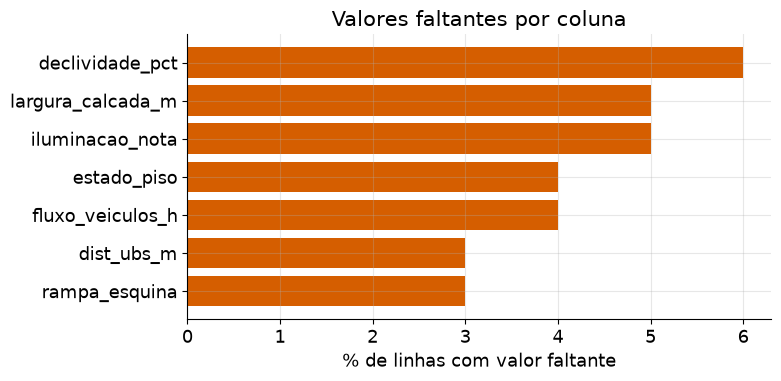

In [4]:
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values()
print((faltantes / len(df) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(faltantes.index, faltantes.values / len(df) * 100, color=LARANJA)
ax.set_xlabel("% de linhas com valor faltante")
ax.set_title("Valores faltantes por coluna")
plt.tight_layout(); plt.show()

Há entre 3 % e 6 % de valores faltantes em algumas colunas. **Não vamos apagar essas linhas** (perderíamos dados)
**e também não vamos preencher agora**: o preenchimento será feito dentro do Pipeline, depois da divisão treino/teste
(ver seção 4, é isso que evita o vazamento de dados).

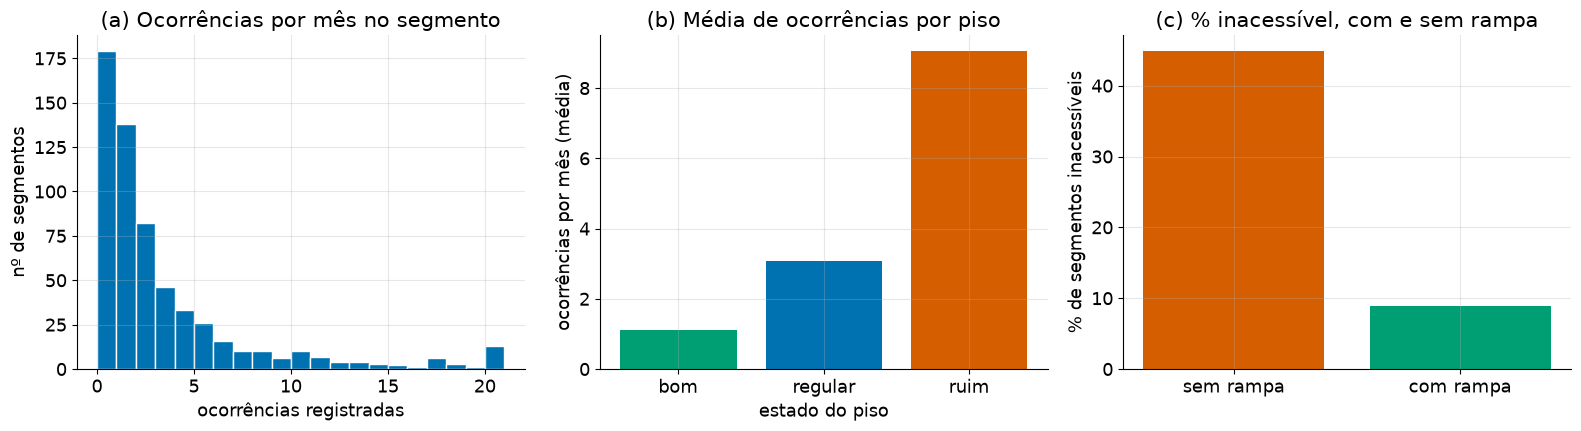

% de segmentos inacessíveis na base: 22.5 %


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) como são as ocorrências por mês
ax[0].hist(df["ocorrencias_mes"], bins=range(0, 22), color=AZUL, edgecolor="white")
ax[0].set_title("(a) Ocorrências por mês no segmento")
ax[0].set_xlabel("ocorrências registradas"); ax[0].set_ylabel("nº de segmentos")

# (b) ocorrências médias por estado do piso
ordem = ["bom", "regular", "ruim"]
media_piso = df.groupby("estado_piso")["ocorrencias_mes"].mean().reindex(ordem)
ax[1].bar(ordem, media_piso.values, color=[VERDE, AZUL, LARANJA])
ax[1].set_title("(b) Média de ocorrências por piso")
ax[1].set_xlabel("estado do piso"); ax[1].set_ylabel("ocorrências por mês (média)")

# (c) % de segmentos inacessíveis com e sem rampa
inac_rampa = df.groupby("rampa_esquina")["inacessivel_cadeira"].mean() * 100
ax[2].bar(["sem rampa", "com rampa"], inac_rampa.values, color=[LARANJA, VERDE])
ax[2].set_title("(c) % inacessível, com e sem rampa")
ax[2].set_ylabel("% de segmentos inacessíveis")

plt.tight_layout(); plt.show()
print("% de segmentos inacessíveis na base:", round(df["inacessivel_cadeira"].mean() * 100, 1), "%")

**Leitura rápida dos gráficos:**
- (a) a maioria dos segmentos tem poucas ocorrências, mas há uma cauda de segmentos bem problemáticos.
- (b) piso ruim concentra mais ocorrências.
- (c) sem rampa na esquina, a chance de ser inacessível é bem maior.

Isso é só olhar os dados. Os modelos abaixo medem o efeito de cada fator **mantendo os outros iguais**.

## 4. Preparação dos dados e divisão treino/teste (sem vazamento)

**O que é vazamento de dados?** É quando informação do conjunto de **teste** "escapa" para o treino. O caso mais comum:
calcular a média (para preencher faltantes) ou o desvio-padrão (para escalar) usando a base **inteira** antes de dividir.
Aí o modelo já "viu" um pouco do teste e a nota fica otimista demais.

**Como evitamos aqui (3 regras):**
1. **Primeiro dividimos** em treino (75 %) e teste (25 %), antes de qualquer preenchimento ou escala.
2. Toda a preparação (preencher faltantes, escalar, transformar texto em colunas) fica **dentro de um `Pipeline` do scikit-learn**.
   O `fit` do Pipeline aprende mediana, média e desvio **só com o treino**. No teste só se aplica (`transform`).
3. Na validação cruzada o Pipeline é reajustado em cada rodada, então também não vaza.

**Escolhas de preparação:**
| Tipo de coluna | O que fazemos | Por quê |
|---|---|---|
| Números (declividade, largura, iluminação, fluxos, distância) | preencher com a **mediana** e **padronizar** | a mediana é pouco afetada por valores extremos; padronizar deixa os coeficientes comparáveis |
| Sim/não (rampa, semáforo, obstáculos) | preencher com o valor **mais frequente** | não faz sentido uma "média" de 0 e 1 |
| Texto (estado do piso: bom/regular/ruim) | preencher com o mais frequente e criar colunas 0/1 (one-hot); **"bom" é a referência** | regressão só entende números |

In [6]:
colunas_num = ["declividade_pct", "largura_calcada_m", "iluminacao_nota",
               "fluxo_veiculos_h", "fluxo_pedestres_h", "dist_ubs_m"]
colunas_bin = ["rampa_esquina", "semaforo_pedestres", "obstaculos_calcada"]
colunas_cat = ["estado_piso"]

X = df[colunas_num + colunas_bin + colunas_cat]
y_num = df["ocorrencias_mes"]          # alvo da regressão linear
y_bin = df["inacessivel_cadeira"]      # alvo da regressão logística

# 1) DIVIDIR PRIMEIRO. stratify mantém a mesma proporção de inacessíveis no treino e no teste.
X_treino, X_teste, yn_treino, yn_teste, yb_treino, yb_teste = train_test_split(
    X, y_num, y_bin, test_size=0.25, random_state=42, stratify=y_bin)

print("Treino:", X_treino.shape, "| Teste:", X_teste.shape)
print("% inacessível no treino:", round(yb_treino.mean() * 100, 1), "| no teste:", round(yb_teste.mean() * 100, 1))
print("Faltantes no treino:", int(X_treino.isna().sum().sum()), "| no teste:", int(X_teste.isna().sum().sum()))

Treino: (450, 10) | Teste: (150, 10)
% inacessível no treino: 22.4 | no teste: 22.7
Faltantes no treino: 138 | no teste: 42


In [7]:
# 2) PREPARAÇÃO DENTRO DO PIPELINE (aprende só com o treino)
prep_num = Pipeline([("preencher", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler())])
prep_bin = Pipeline([("preencher", SimpleImputer(strategy="most_frequent"))])
prep_cat = Pipeline([("preencher", SimpleImputer(strategy="most_frequent")),
                     ("one_hot", OneHotEncoder(categories=[["bom", "regular", "ruim"]], drop="first"))])

preparacao = ColumnTransformer([("num", prep_num, colunas_num),
                                ("bin", prep_bin, colunas_bin),
                                ("cat", prep_cat, colunas_cat)])

def tabela_coeficientes(modelo, coef):
    # Junta nome da variável, coeficiente (variável padronizada) e efeito por unidade original.
    prep = modelo.named_steps["prep"]
    nomes = [n.split("__")[-1] for n in prep.get_feature_names_out()]
    desvios = prep.named_transformers_["num"].named_steps["escalar"].scale_
    escala = np.concatenate([desvios, np.ones(len(nomes) - len(desvios))])
    t = pd.DataFrame({"variavel": nomes, "coef_padronizado": coef, "coef_unidade_original": coef / escala})
    return t.set_index("variavel")

print("Pipeline de preparação criado (ainda não foi ajustado a nenhum dado).")

Pipeline de preparação criado (ainda não foi ajustado a nenhum dado).


## 5. Regressão linear: prever as ocorrências por mês

**Ideia:** `ocorrencias_mes = b0 + b1·declividade + b2·largura + ...`. O modelo escolhe os coeficientes `b` que
minimizam o erro quadrático no treino. Depois avaliamos no **teste**, que o modelo nunca viu.

**Métricas:**
- **MAE**: erro médio absoluto, em "ocorrências por mês" (fácil de explicar).
- **RMSE**: parecido com o MAE, mas pune mais os erros grandes.
- **R²**: fração da variação das ocorrências que o modelo explica (1 = perfeito, 0 = igual a chutar a média).

In [8]:
modelo_lin = Pipeline([("prep", preparacao), ("reg", LinearRegression())])
modelo_lin.fit(X_treino, yn_treino)                 # aprende mediana, escala e coeficientes SÓ no treino

pred_lin = modelo_lin.predict(X_teste)              # no teste, o Pipeline só aplica (transform) e prevê

# Comparação com o "chute" mais simples: sempre prever a média do treino
base_lin = DummyRegressor(strategy="mean").fit(X_treino, yn_treino)
pred_base = base_lin.predict(X_teste)

def metricas_reg(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R²": r2_score(y, p)}

resultado_lin = pd.DataFrame({"Regressão linear": metricas_reg(yn_teste, pred_lin),
                              "Chute (média)": metricas_reg(yn_teste, pred_base)}).round(3)
print("Métricas no TESTE:")
resultado_lin

Métricas no TESTE:


,Regressão linear,Chute (média)
MAE,1.763,3.093
RMSE,2.664,4.663
R²,0.674,-0.000


In [9]:
# Validação cruzada no treino: o Pipeline é reajustado em cada rodada (sem vazamento)
r2_cv = cross_val_score(modelo_lin, X_treino, yn_treino, cv=5, scoring="r2")
print("R² em 5 rodadas:", r2_cv.round(3), "| média:", r2_cv.mean().round(3))

R² em 5 rodadas: [0.646 0.674 0.638 0.508 0.681] | média: 0.63


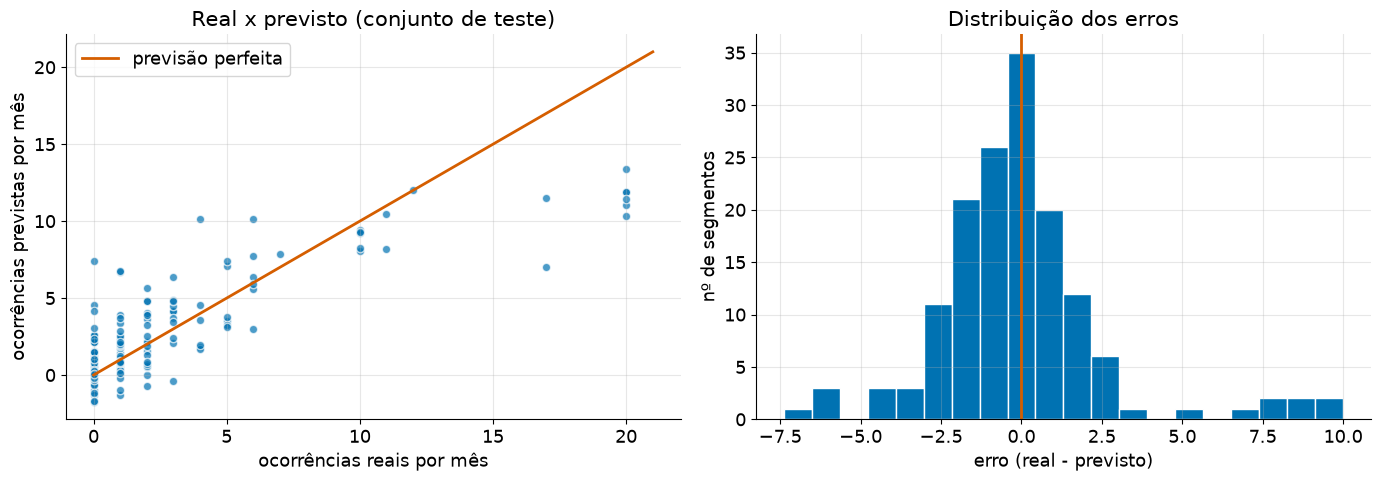

Previsões negativas no teste (impossível para contagem): 17


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(yn_teste, pred_lin, color=AZUL, alpha=0.7, edgecolor="white")
lim = max(yn_teste.max(), pred_lin.max()) + 1
ax[0].plot([0, lim], [0, lim], color=LARANJA, linewidth=2, label="previsão perfeita")
ax[0].set_xlabel("ocorrências reais por mês"); ax[0].set_ylabel("ocorrências previstas por mês")
ax[0].set_title("Real x previsto (conjunto de teste)"); ax[0].legend()

erro = yn_teste - pred_lin
ax[1].hist(erro, bins=20, color=AZUL, edgecolor="white")
ax[1].axvline(0, color=LARANJA, linewidth=2)
ax[1].set_xlabel("erro (real - previsto)"); ax[1].set_ylabel("nº de segmentos")
ax[1].set_title("Distribuição dos erros")
plt.tight_layout(); plt.show()
print("Previsões negativas no teste (impossível para contagem):", int((pred_lin < 0).sum()))

**Como ler:**
- Os pontos perto da linha laranja são acertos. O modelo acompanha a tendência, mas **erra mais nos segmentos com muitas ocorrências**
  (a contagem tem muita variação aleatória, e a regressão linear é uma aproximação).
- Algumas previsões saem negativas. Contagem não pode ser negativa; na prática, **tratamos como 0**.

In [11]:
coef_lin = tabela_coeficientes(modelo_lin, modelo_lin.named_steps["reg"].coef_)
print("Intercepto (b0):", round(modelo_lin.named_steps["reg"].intercept_, 3))
coef_lin.round(3).sort_values("coef_padronizado", ascending=False)

Intercepto (b0): 2.535


,coef_padronizado,coef_unidade_original
variavel,,
estado_piso_ruim,3.897,3.897
obstaculos_calcada,1.615,1.615
declividade_pct,0.997,0.355
fluxo_pedestres_h,0.860,0.008
estado_piso_regular,0.738,0.738
fluxo_veiculos_h,0.422,0.005
semaforo_pedestres,0.030,0.030
dist_ubs_m,-0.147,-0.001
largura_calcada_m,-0.261,-0.583


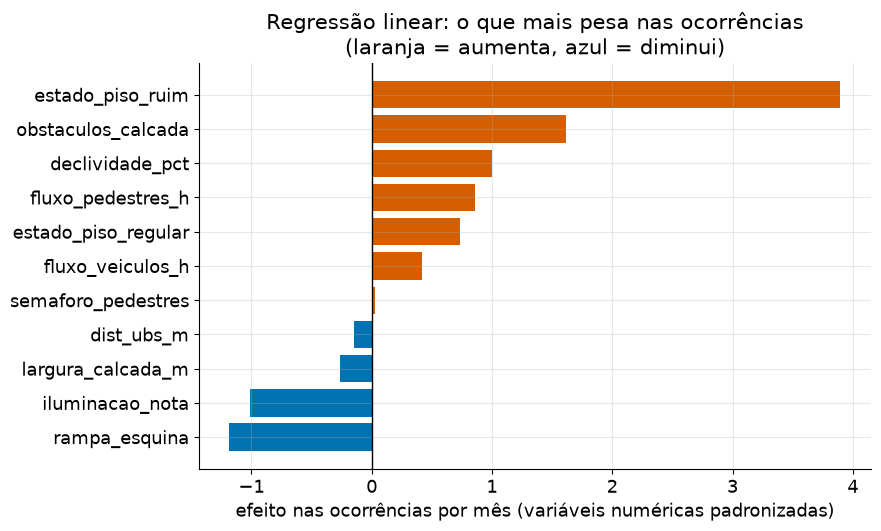

In [12]:
ordenado = coef_lin["coef_padronizado"].sort_values()
cores = [LARANJA if v > 0 else AZUL for v in ordenado.values]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(ordenado.index, ordenado.values, color=cores)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("efeito nas ocorrências por mês (variáveis numéricas padronizadas)")
ax.set_title("Regressão linear: o que mais pesa nas ocorrências\n(laranja = aumenta, azul = diminui)")
plt.tight_layout(); plt.show()

### Interpretação da regressão linear
**Desempenho no teste:** MAE ≈ 1,76 e RMSE ≈ 2,66 ocorrências por mês, **R² ≈ 0,67**. O "chute da média" erra 3,09 em média (MAE),
então o modelo reduz o erro quase pela metade. Ele explica cerca de **67 %** da variação das ocorrências.
A validação cruzada (R² médio ≈ 0,63) é parecida, o que indica que o resultado **não é sorte da divisão** treino/teste.

**Coeficientes** (coluna `coef_unidade_original`: efeito de cada fator **mantendo os outros iguais**):
| Fator | Efeito nas ocorrências por mês |
|---|---|
| Piso ruim (comparado a piso bom) | **+3,9** (o maior efeito) |
| Obstáculos na calçada | **+1,6** |
| Rampa na esquina | **−1,2** |
| Iluminação (cada ponto a mais na nota 1 a 5) | **−1,0** |
| Declividade (cada ponto percentual a mais) | **+0,36** |
| Largura da calçada (cada metro a mais) | **−0,58** |
| Fluxo de pedestres (cada 100 pedestres/h a mais) | **+0,8** (veja o aviso abaixo) |
| Distância até a UBS e semáforo | perto de zero, quase não ajudam a prever |

**Aviso importante:** o efeito do fluxo de pedestres provavelmente é **viés de registro**: onde passa mais gente, mais gente registra a ocorrência.
Isso não quer dizer que a calçada seja pior. O coeficiente mostra **associação**, não causa.

## 6. Regressão logística: chance de o segmento ser inacessível

**Ideia:** quando o alvo é sim/não, a regressão linear não serve (ela pode dar -0,3 ou 1,7). A logística calcula uma **probabilidade
entre 0 e 1** de o segmento ser inacessível. Se a probabilidade passa de um **limiar** (começamos com 0,5), classificamos como "inacessível".

**Métricas (a "classe positiva" é inacessível):**
- **Matriz de confusão**: quantos acertos e erros de cada tipo.
- **Precisão**: dos segmentos que o modelo marcou como inacessíveis, quantos realmente eram.
- **Recall (sensibilidade)**: dos segmentos realmente inacessíveis, quantos o modelo achou.
- **F1**: média entre precisão e recall (um número só para os dois).

**Por que não olhar só a acurácia?** Só uns 22 % dos segmentos são inacessíveis. Um modelo "preguiçoso" que diz que *tudo é acessível*
acertaria cerca de 78 % e **não acharia nenhum problema**. Por isso precisão, recall e F1 importam mais.

In [13]:
modelo_log = Pipeline([("prep", preparacao), ("clf", LogisticRegression(max_iter=1000))])
modelo_log.fit(X_treino, yb_treino)

proba_teste = modelo_log.predict_proba(X_teste)[:, 1]     # probabilidade de ser inacessível
pred_log = (proba_teste >= 0.5).astype(int)

# O "modelo preguiçoso" para comparar
preguicoso = DummyClassifier(strategy="most_frequent").fit(X_treino, yb_treino)
pred_pregui = preguicoso.predict(X_teste)

def metricas_cls(y, p):
    return {"Acurácia": accuracy_score(y, p), "Precisão": precision_score(y, p, zero_division=0),
            "Recall": recall_score(y, p), "F1": f1_score(y, p)}

resultado_log = pd.DataFrame({"Regressão logística": metricas_cls(yb_teste, pred_log),
                              "Modelo preguiçoso (tudo acessível)": metricas_cls(yb_teste, pred_pregui)}).round(3)
print("Métricas no TESTE (limiar 0,5):")
resultado_log

Métricas no TESTE (limiar 0,5):


,Regressão logística,Modelo preguiçoso (tudo acessível)
Acurácia,0.840,0.773
Precisão,0.750,0.000
Recall,0.441,0.000
F1,0.556,0.000


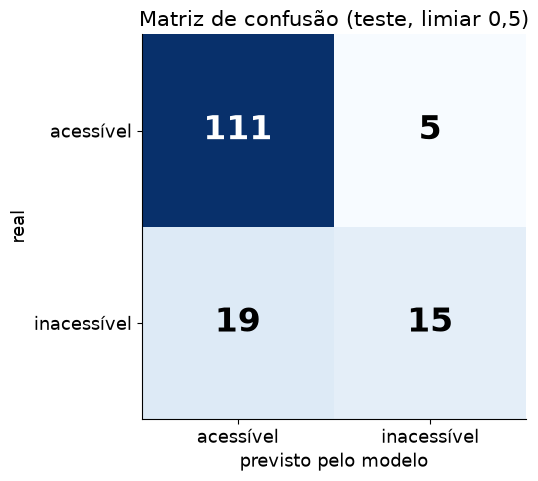

Acertou 111 acessíveis e 15 inacessíveis.
Falsos positivos (disse inacessível, mas era acessível): 5
Falsos negativos (disse acessível, mas era inacessível): 19

              precision    recall  f1-score   support

   acessível      0.854     0.957     0.902       116
 inacessível      0.750     0.441     0.556        34

    accuracy                          0.840       150
   macro avg      0.802     0.699     0.729       150
weighted avg      0.830     0.840     0.824       150

AUC-ROC (0,5 = chute, 1 = perfeito): 0.861


In [14]:
cm = confusion_matrix(yb_teste, pred_log)
rotulos = ["acessível", "inacessível"]

fig, ax = plt.subplots(figsize=(5.8, 5))
ax.imshow(cm, cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=24, fontweight="bold",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], rotulos); ax.set_yticks([0, 1], rotulos)
ax.set_xlabel("previsto pelo modelo"); ax.set_ylabel("real")
ax.set_title("Matriz de confusão (teste, limiar 0,5)")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Acertou {tn} acessíveis e {tp} inacessíveis.")
print(f"Falsos positivos (disse inacessível, mas era acessível): {fp}")
print(f"Falsos negativos (disse acessível, mas era inacessível): {fn}")
print()
print(classification_report(yb_teste, pred_log, target_names=rotulos, digits=3))
print("AUC-ROC (0,5 = chute, 1 = perfeito):", round(roc_auc_score(yb_teste, proba_teste), 3))

### Interpretação da matriz de confusão e das métricas
- **Acertos:** 111 acessíveis e 15 inacessíveis. **Erros:** 5 falsos positivos e 19 falsos negativos.
- **Precisão 0,75:** quando o modelo diz "inacessível", acerta 3 de cada 4 vezes.
- **Recall 0,44:** ele só achou **menos da metade** dos segmentos realmente inacessíveis. Esse é o ponto fraco com o limiar 0,5.
- **F1 0,56** e **AUC 0,86**: o modelo separa bem os dois grupos quando olhamos as probabilidades, mas o corte de 0,5 é rígido demais.
- **Comparação:** a acurácia (0,84) só é um pouco melhor que a do modelo preguiçoso (0,77), mas o preguiçoso tem recall 0. O modelo agrega valor de verdade.

**Escolha do limiar:** para a CaminhoSeguro, **deixar passar um segmento perigoso é pior que vistoriar um que estava bom**.
Por isso testamos limiares menores. Para não "espiar" o teste, **o limiar é escolhido com validação cruzada só no treino**;
o teste é usado no fim, uma única vez, para conferir.

In [15]:
# Qual limiar usar? Escolhemos com validação cruzada NO TREINO (sem olhar o teste).
# cross_val_predict dá, para cada segmento do treino, a probabilidade prevista por um modelo que NÃO o viu.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
proba_cv = cross_val_predict(modelo_log, X_treino, yb_treino, cv=cv, method="predict_proba")[:, 1]

linhas = []
for lim in [0.5, 0.4, 0.3, 0.2]:
    p = (proba_cv >= lim).astype(int)
    linhas.append({"limiar": lim, "apontados (treino)": int(p.sum()),
                   "precisão": precision_score(yb_treino, p), "recall": recall_score(yb_treino, p),
                   "F1": f1_score(yb_treino, p)})
tab_limiar = pd.DataFrame(linhas).set_index("limiar").round(3)
print("Limiares avaliados com validação cruzada no TREINO:")
display(tab_limiar)

# Regra de triagem: o MENOR limiar em que pelo menos metade dos apontados é inacessível de verdade (precisão >= 0,5)
limiar_triagem = tab_limiar[tab_limiar["precisão"] >= 0.5].index.min()
p_triagem = (proba_teste >= limiar_triagem).astype(int)
print(f"Limiar de triagem escolhido no treino: {limiar_triagem}")
print("Conferência no TESTE (uma única vez):")
pd.DataFrame({f"limiar 0,5": metricas_cls(yb_teste, pred_log),
              f"limiar {limiar_triagem} (triagem)": metricas_cls(yb_teste, p_triagem)}).round(3)


Limiares avaliados com validação cruzada no TREINO:


,apontados (treino),precisão,recall,F1
limiar,,,,
0.5,81,0.704,0.564,0.626
0.4,96,0.667,0.634,0.650
0.3,120,0.625,0.743,0.679
0.2,151,0.543,0.812,0.651


Limiar de triagem escolhido no treino: 0.2
Conferência no TESTE (uma única vez):


,"limiar 0,5",limiar 0.2 (triagem)
Acurácia,0.840,0.780
Precisão,0.750,0.511
Recall,0.441,0.706
F1,0.556,0.593


**Leitura da escolha do limiar:**
- Na validação cruzada do treino, baixar o limiar de 0,5 para **0,2** faz o recall subir de 0,56 para 0,81, com precisão ainda acima de 0,5
  (de cada 2 segmentos apontados, pelo menos 1 é inacessível de verdade). Pela regra definida antes de olhar o teste, o limiar de triagem é **0,2**.
- **Conferência no teste (feita uma vez só):** com 0,2, o recall vai de 0,44 para **0,71** e o F1 de 0,56 para **0,59**; a precisão cai para 0,51.
  Ou seja, o modelo passa a achar 7 de cada 10 segmentos inacessíveis, em troca de mais vistorias que não encontram problema.
- **Uso:** limiar **0,5** quando a decisão é uma obra cara (precisa de mais certeza); limiar **0,2** para a triagem de vistorias e alertas no app.
  Com só 34 segmentos inacessíveis no teste, esses números oscilam: tratamos como ordem de grandeza.

In [16]:
coef_log = tabela_coeficientes(modelo_log, modelo_log.named_steps["clf"].coef_[0])
coef_log["razao_de_chances"] = np.exp(coef_log["coef_unidade_original"])   # efeito por unidade original, em "vezes"
coef_log.round(3).sort_values("coef_padronizado", ascending=False)

,coef_padronizado,coef_unidade_original,razao_de_chances
variavel,,,
estado_piso_ruim,0.955,0.955,2.599
obstaculos_calcada,0.788,0.788,2.199
declividade_pct,0.633,0.225,1.252
estado_piso_regular,0.415,0.415,1.514
fluxo_veiculos_h,0.234,0.003,1.003
iluminacao_nota,0.129,0.127,1.136
fluxo_pedestres_h,0.059,0.001,1.001
dist_ubs_m,0.014,0.000,1.000
semaforo_pedestres,-0.402,-0.402,0.669


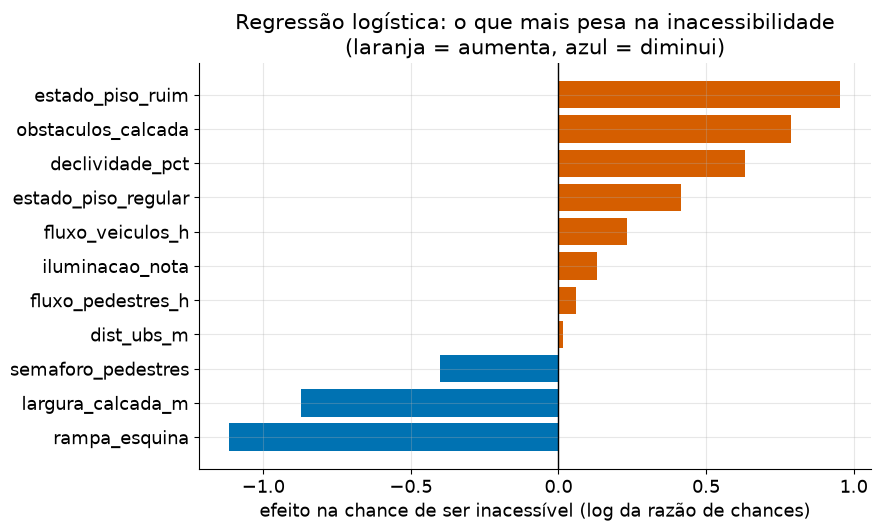

In [17]:
ordenado = coef_log["coef_padronizado"].sort_values()
cores = [LARANJA if v > 0 else AZUL for v in ordenado.values]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(ordenado.index, ordenado.values, color=cores)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("efeito na chance de ser inacessível (log da razão de chances)")
ax.set_title("Regressão logística: o que mais pesa na inacessibilidade\n(laranja = aumenta, azul = diminui)")
plt.tight_layout(); plt.show()

### Interpretação dos coeficientes (regressão logística)
A **razão de chances** diz quantas vezes a chance de "inacessível" é multiplicada quando o fator aumenta uma unidade (outros fatores iguais):
- **Piso ruim:** chance **2,6 vezes maior** que piso bom. **Piso regular:** 1,5 vez.
- **Obstáculos na calçada:** **2,2 vezes** maior.
- **Declividade:** cada ponto percentual a mais aumenta a chance em cerca de **25 %**.
- **Rampa na esquina:** a chance cai para cerca de **1/3** (razão 0,33). É o fator controlável de maior efeito protetor.
- **Largura:** cada metro a mais multiplica a chance por **0,14** (calçada larga protege muito).
- **Semáforo de pedestres:** razão 0,67, efeito pequeno.
- **Fluxo de veículos:** razão ≈ 1,3 a cada 100 veículos/h. Isso é **associação, não causa**: ruas movimentadas tendem a ter calçada pior, mas o carro não "causa" a inacessibilidade.
- **Iluminação:** razão 1,14 (sinal positivo, pequeno e sem sentido físico: iluminação melhor não deveria aumentar a chance). É um sinal de **ruído** nos dados, mais um motivo para não tratar coeficiente como causa.
- **Distância até a UBS e fluxo de pedestres:** razão ≈ 1, ou seja, não ajudam.

**Fatores que a prefeitura consegue mudar** (piso, rampa, obstáculos) têm efeito forte. **Declividade e largura** pesam muito,
mas dependem do terreno e do projeto da calçada.

### Teste mais duro: prever um trecho que o modelo nunca viu
Os 30 segmentos de um mesmo trecho se parecem entre si. No `train_test_split` aleatório, o treino já viu "vizinhos" de cada segmento do teste,
então a nota pode ficar otimista. Aqui usamos **validação cruzada por grupo** (`GroupKFold`): cada rodada deixa **trechos inteiros** de fora do treino.
É o cenário real de uso, em que o app precisa prever um trecho novo da cidade. (Limiares fixos 0,5 e 0,2, sem ajuste nesta etapa.)

In [18]:
from sklearn.model_selection import GroupKFold

grupos = df["local_inicio"] + " → " + df["local_fim"]          # 20 trechos = 20 grupos
gkf = GroupKFold(n_splits=5)

# Cada previsão vem de um modelo que não viu nenhum segmento daquele trecho
pred_g = cross_val_predict(modelo_lin, X, y_num, cv=gkf, groups=grupos)
proba_g = cross_val_predict(modelo_log, X, y_bin, cv=gkf, groups=grupos, method="predict_proba")[:, 1]

m = metricas_reg(y_num, pred_g)
print("Regressão linear (trechos inéditos): MAE %.2f | RMSE %.2f | R² %.2f" % (m["MAE"], m["RMSE"], m["R²"]))
print("Regressão logística (trechos inéditos): AUC = %.3f" % roc_auc_score(y_bin, proba_g))
pd.DataFrame({f"limiar {l}".replace(".", ","): metricas_cls(y_bin, (proba_g >= l).astype(int)) for l in (0.5, 0.2)}).round(3)

Regressão linear (trechos inéditos): MAE 1.86 | RMSE 2.59 | R² 0.65
Regressão logística (trechos inéditos): AUC = 0.869


,"limiar 0,5","limiar 0,2"
Acurácia,0.852,0.802
Precisão,0.717,0.542
Recall,0.563,0.763
F1,0.631,0.634


**Leitura:** com trechos inteiros fora do treino, a regressão linear fica com R² ≈ 0,65 (contra 0,67 no teste aleatório) e a logística com AUC ≈ 0,87 (contra 0,86); com limiar 0,2 o recall é ≈ 0,76 e a precisão ≈ 0,54.
Ou seja, os resultados **quase não mudam**: o desempenho não depende de o modelo ter visto segmentos vizinhos. Isso dá mais confiança, mas continua valendo o aviso de que a base é simulada (seção 8).

## 7. Das previsões à decisão

Agora usamos as previsões para decidir **onde agir primeiro**. Passos (todos com Pipeline, sem vazamento):
1. Como os modelos já foram avaliados no teste, **reajustamos os dois com todos os 600 segmentos** (prática comum depois da validação).
2. Calculamos, para cada segmento, a **probabilidade de ser inacessível** e as **ocorrências esperadas por mês**.
3. Agrupamos por **trecho** (os mesmos 20 trechos da matéria de rotas) e montamos um ranking.
4. Simulamos o **"E se?"**: se a subprefeitura consertar os fatores que dá para mudar, quanto sobe o **% de trechos acessíveis**?

In [19]:
# 1) Modelos finais com todos os dados (a avaliação honesta já foi feita no teste)
final_log = clone(modelo_log).fit(X, y_bin)
final_lin = clone(modelo_lin).fit(X, y_num)

# 2) Previsões por segmento
res = df[["id_segmento", "local_inicio", "local_fim", "ocorrencias_mes", "inacessivel_cadeira"]].copy()
res["p_inacessivel"] = final_log.predict_proba(X)[:, 1]
res["ocorr_prevista"] = np.clip(final_lin.predict(X), 0, None)        # contagem não é negativa
res["trecho"] = (res["local_inicio"] + " → " + res["local_fim"]).str.replace("_", " ")

# 3) Ranking por trecho
trechos = res.groupby("trecho").agg(
    segmentos=("id_segmento", "count"),
    pct_inacessivel_real=("inacessivel_cadeira", lambda s: s.mean() * 100),
    pct_inacessivel_previsto=("p_inacessivel", lambda s: s.mean() * 100),
    ocorr_reais_mes=("ocorrencias_mes", "mean"),
    ocorr_previstas_mes=("ocorr_prevista", "mean"),
).round(1).sort_values("pct_inacessivel_previsto", ascending=False)

print("Top 8 trechos para priorizar (ordenados pela % de inacessibilidade prevista):")
trechos.head(8)

Top 8 trechos para priorizar (ordenados pela % de inacessibilidade prevista):


,segmentos,pct_inacessivel_real,pct_inacessivel_previsto,ocorr_reais_mes,ocorr_previstas_mes
trecho,,,,,
Casa Dona Maria → Escola,30,76.7,72.7,9.8,9.4
Posto de Saude → Centro Comunitario,30,70.0,67.7,8.3,8.2
Casa Dona Maria → Viaduto,30,50.0,59.4,11.2,9.6
Escola → Metro Brigadeiro,30,60.0,55.6,4.8,6.0
Viaduto → Metro Brigadeiro,30,53.3,47.2,6.8,6.3
Praca 14 Bis → Biblioteca,30,23.3,18.0,2.4,2.9
Escola → Mercado,30,16.7,17.5,2.5,3.9
FIAP Paulista → Biblioteca,30,20.0,14.1,1.6,1.8


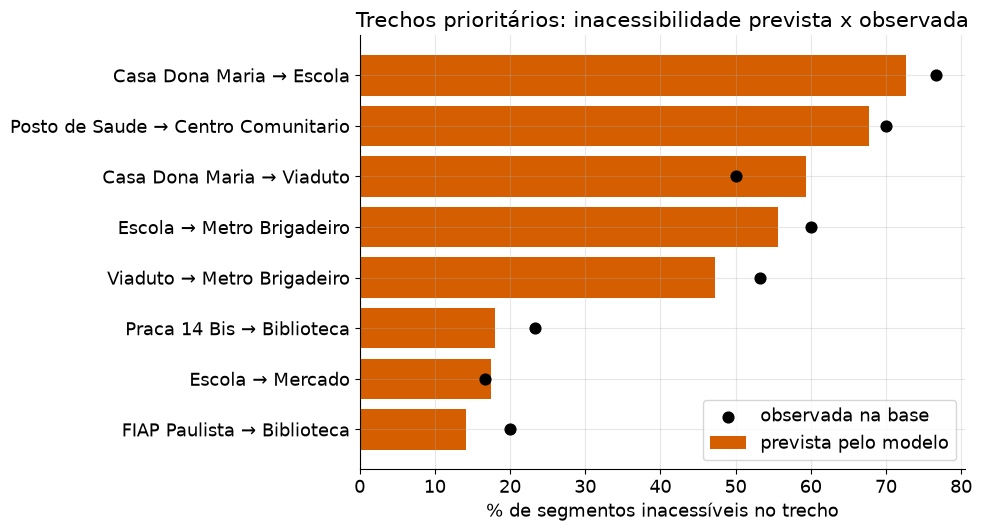

In [20]:
top = trechos.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index, top["pct_inacessivel_previsto"], color=LARANJA, label="prevista pelo modelo")
ax.scatter(top["pct_inacessivel_real"], top.index, color="black", zorder=3, s=60, label="observada na base")
ax.set_xlabel("% de segmentos inacessíveis no trecho")
ax.set_title("Trechos prioritários: inacessibilidade prevista x observada")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [21]:
# Quais trechos têm MAIS problema do que a comunidade registra? (possível falta de registro)
trechos["falta_de_registro"] = (trechos["ocorr_previstas_mes"] - trechos["ocorr_reais_mes"]).round(1)
print("Trechos onde o modelo espera mais ocorrências do que as registradas (diferença positiva):")
trechos.sort_values("falta_de_registro", ascending=False)[["ocorr_reais_mes", "ocorr_previstas_mes", "falta_de_registro"]].head(5)

Trechos onde o modelo espera mais ocorrências do que as registradas (diferença positiva):


,ocorr_reais_mes,ocorr_previstas_mes,falta_de_registro
trecho,,,
Escola → Mercado,2.5,3.9,1.4
Escola → Metro Brigadeiro,4.8,6.0,1.2
Biblioteca → Centro Comunitario,1.3,2.1,0.8
Farmacia → Mercado,1.2,2.0,0.8
FIAP Paulista → Farmacia,0.6,1.2,0.6


### "E se?": impacto esperado no indicador "% de trechos acessíveis"
**Premissa da simulação:** a subprefeitura trata os **K segmentos com maior probabilidade de serem inacessíveis**, mudando só o que
dá para consertar com obra simples: **construir rampa na esquina, trocar o piso ruim por piso bom e retirar obstáculos**.
Declividade e largura da calçada **não mudam** (são do terreno). Depois o modelo recalcula a probabilidade desses segmentos.

Comparamos com a estratégia de **escolher K segmentos ao acaso**, para ver se prever vale a pena.

In [22]:
def pct_acessivel_esperado(probabilidades):
    # % esperado de segmentos acessíveis = média de (1 - probabilidade de ser inacessível)
    return (1 - probabilidades).mean() * 100

def aplicar_obras(X_in, indices):
    X_novo = X_in.copy()
    X_novo.loc[indices, "rampa_esquina"] = 1
    X_novo.loc[indices, "obstaculos_calcada"] = 0
    X_novo.loc[indices, "estado_piso"] = "bom"
    return X_novo

p_antes = final_log.predict_proba(X)[:, 1]
rng = np.random.default_rng(7)
ordem_risco = res.sort_values("p_inacessivel", ascending=False).index

linhas = [{"K (segmentos tratados)": 0, "% acessível (priorizando)": pct_acessivel_esperado(p_antes),
           "% acessível (ao acaso)": pct_acessivel_esperado(p_antes)}]
for k in [30, 60, 90, 120]:
    prioridade = ordem_risco[:k]
    p_prior = final_log.predict_proba(aplicar_obras(X, prioridade))[:, 1]
    ganhos_acaso = []
    for _ in range(200):
        sorteio = rng.choice(X.index, size=k, replace=False)
        ganhos_acaso.append(pct_acessivel_esperado(final_log.predict_proba(aplicar_obras(X, sorteio))[:, 1]))
    linhas.append({"K (segmentos tratados)": k, "% acessível (priorizando)": pct_acessivel_esperado(p_prior),
                   "% acessível (ao acaso)": np.mean(ganhos_acaso)})

cenarios = pd.DataFrame(linhas).set_index("K (segmentos tratados)").round(1)
cenarios["ganho priorizando (pontos %)"] = (cenarios["% acessível (priorizando)"] - cenarios.loc[0, "% acessível (priorizando)"]).round(1)
cenarios["ganho ao acaso (pontos %)"] = (cenarios["% acessível (ao acaso)"] - cenarios.loc[0, "% acessível (ao acaso)"]).round(1)
print(f"% acessível hoje: observado = {(1 - y_bin.mean()) * 100:.1f} % | esperado pelo modelo = {pct_acessivel_esperado(p_antes):.1f} %")
cenarios

% acessível hoje: observado = 77.5 % | esperado pelo modelo = 77.5 %


,% acessível (priorizando),% acessível (ao acaso),ganho priorizando (pontos %),ganho ao acaso (pontos %)
K (segmentos tratados),,,,
0,77.5,77.5,0.0,0.0
30,79.2,78.1,1.7,0.6
60,81.4,78.6,3.9,1.1
90,83.3,79.2,5.8,1.7
120,84.8,79.7,7.3,2.2


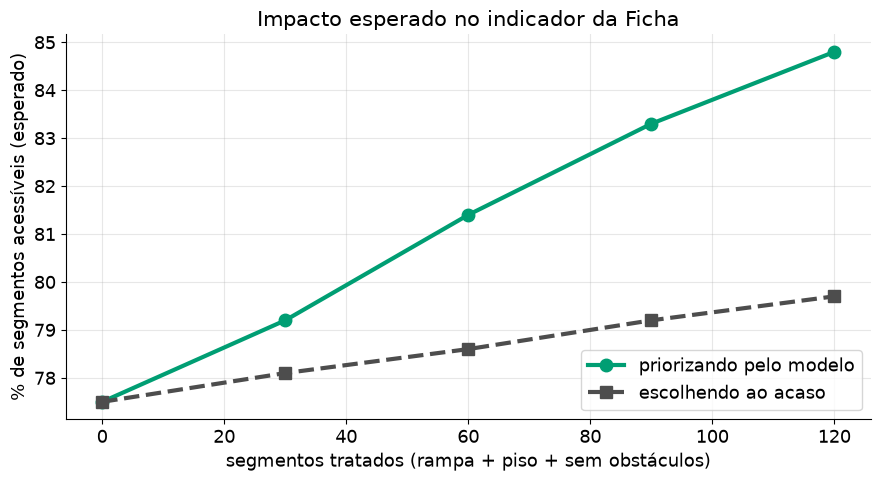

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cenarios.index, cenarios["% acessível (priorizando)"], marker="o", color=VERDE, linewidth=3, markersize=9,
        label="priorizando pelo modelo")
ax.plot(cenarios.index, cenarios["% acessível (ao acaso)"], marker="s", color=CINZA, linewidth=3, markersize=8,
        linestyle="--", label="escolhendo ao acaso")
ax.set_xlabel("segmentos tratados (rampa + piso + sem obstáculos)")
ax.set_ylabel("% de segmentos acessíveis (esperado)")
ax.set_title("Impacto esperado no indicador da Ficha")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [24]:
# Dos segmentos de maior risco, quantos continuam arriscados depois das obras? (o problema é o terreno)
K = 60
prioridade = ordem_risco[:K]
p_depois = final_log.predict_proba(aplicar_obras(X, prioridade))[:, 1]
ainda = int((p_depois[X.index.get_indexer(prioridade)] >= 0.5).sum())
print(f"Dos {K} segmentos tratados, {ainda} ainda ficam com probabilidade >= 50 % de serem inacessíveis (declividade/largura).")
print("Declividade média desses segmentos:", round(X.loc[prioridade, "declividade_pct"].mean(), 1), "% (limite da NBR 9050 para rampa: 8,33 %)")
print("Largura média da calçada desses segmentos:", round(X.loc[prioridade, "largura_calcada_m"].mean(), 2), "m (mínimo da NBR 9050: 1,20 m)")

Dos 60 segmentos tratados, 27 ainda ficam com probabilidade >= 50 % de serem inacessíveis (declividade/largura).
Declividade média desses segmentos: 9.1 % (limite da NBR 9050 para rampa: 8,33 %)
Largura média da calçada desses segmentos: 1.04 m (mínimo da NBR 9050: 1,20 m)


## 8. Recomendações para a subprefeitura e para o app

### A. Para a subprefeitura: o que priorizar
1. **Trechos prioritários** (ranking da seção 7): **Casa da Dona Maria → Escola** (≈ 73 % previsto de segmentos inacessíveis),
   **Posto de Saúde → Centro Comunitário** (≈ 68 %), **Casa da Dona Maria → Viaduto** (≈ 59 %), **Escola → Metrô Brigadeiro** (≈ 56 %)
   e **Viaduto → Metrô Brigadeiro** (≈ 47 %). Os três trechos que a matéria de rotas já marca como não acessíveis aparecem entre os cinco primeiros.
   A mochila da matéria de Dynamic Programming já tem rampa para os três (Casa → Escola, Escola → Metrô e Posto → Centro), mas com
   R$ 50 mil escolhe só a de Casa → Escola. **A análise indica que Posto → Centro e Escola → Metrô devem ser as próximas obras**
   quando houver orçamento (ou ter o benefício revisto na mochila, já que estão entre os trechos de maior risco).
   O Posto de Saúde → Centro Comunitário liga a dona Maria à UBS e ao centro comunitário, então tem efeito direto na **saúde (ODS 3)**.
2. **Obras simples nos segmentos de maior risco:** rampa na esquina, trocar piso ruim e retirar obstáculos.
3. **Impacto esperado no indicador "% de trechos acessíveis"** (calculado por segmento de calçada, a partir de 77,5 % hoje):

| Segmentos tratados | Priorizando pelo modelo | Escolhendo ao acaso |
|---|---|---|
| 30 (5 %) | 79,2 % (+1,7 pontos) | 78,1 % (+0,6) |
| **60 (10 %)** | **81,4 % (+3,9 pontos)** | 78,6 % (+1,1) |
| 90 (15 %) | 83,3 % (+5,8 pontos) | 79,2 % (+1,7) |
| 120 (20 %) | 84,8 % (+7,3 pontos) | 79,7 % (+2,2) |

   **Priorizar com o modelo rende cerca de 3 vezes o ganho de escolher ao acaso** com o mesmo número de obras (de 2,8 a 3,5 vezes, conforme o K).
4. **Nem tudo se resolve com obra simples:** mesmo depois das obras, **27 dos 60** segmentos de maior risco continuam com chance ≥ 50 % de serem inacessíveis,
   porque a declividade média deles (9,1 %) passa do limite da NBR 9050 (8,33 %) e a largura média (1,04 m) fica abaixo de 1,20 m.
   Esses precisam de **projeto maior** (rampa com corrimão, alargamento da calçada) ou de **rota alternativa**. Sugerimos uma fila separada.
5. **Vistoria em campo para quem ficou no meio:** segmentos com probabilidade entre 20 % e 50 % devem ser vistoriados antes de decidir (limiar de triagem 0,2, seção 6).
6. **Possível falta de registro:** em **Escola → Mercado** e **Escola → Metrô Brigadeiro** o modelo espera mais ocorrências do que a comunidade registrou
   (+1,4 e +1,2 por mês). Vale reforçar a divulgação do app e usar a UBS e o Centro Comunitário como pontos de coleta.

### B. Para o app CaminhoSeguro
1. **Usar a probabilidade de inacessível como peso do trecho** no cálculo da rota acessível (o Dijkstra da matéria de DP), em vez de um risco fixo.
   A probabilidade pode ser atualizada quando entrarem novas ocorrências.
2. **Alertar o usuário:** em segmentos com probabilidade a partir do limiar de triagem (≥ 20 %), mostrar "esta calçada pode ter problema" e já oferecer a rota alternativa.
3. **Pedir confirmação à comunidade** onde a probabilidade é alta e há poucos registros ("esta esquina tem rampa?"). Isso coleta o dado que falta e melhora o modelo.
4. **Simplificar o formulário:** os fatores que mais pesam são **piso, rampa, obstáculos, declividade e largura**. Distância até a UBS e semáforo quase não ajudam.
   Perguntas curtas, letra grande e boa leitura combinam com o público idoso.
5. **Fechar o ciclo:** medir o "% de segmentos acessíveis" antes e depois de cada obra e comparar com o previsto aqui.

### C. Limitações (leia antes de usar os números)
- **Dados simulados.** As relações (por exemplo, "piso ruim aumenta ocorrências") foram **programadas por nós** no gerador, então o modelo "descobriu" o que inventamos.
  **R² 0,67 e a subida de 77,5 % para 81,4 % não valem para a Bela Vista real.** O notebook demonstra o **método**; com dados reais ele serviria de base.
- **Correlação não é causalidade.** O "E se?" assume que consertar piso e rampa muda a probabilidade como os coeficientes indicam.
  Na vida real isso precisa ser testado com medições **antes e depois** das obras.
  O fluxo de veículos, por exemplo, aparece ligado à inacessibilidade, mas não é a causa.
- **Viés nos dados.** O app só recebe registros de quem tem celular e conhece o app: onde passa mais gente aparece mais problema (viés de registro),
  e **locais de idosos sem smartphone ficam invisíveis**. Se só olharmos os registros, podemos **piorar a desigualdade** (ODS 10) em vez de reduzi-la.
  Por isso a recomendação de vistoria em campo e de pontos de coleta presenciais.
- **Poucos dados no teste:** 150 segmentos, só 34 inacessíveis. As métricas variam se mudarmos a divisão. Segmentos do mesmo trecho são parecidos entre si,
  então o teste pode ser mais fácil do que um trecho totalmente novo.
- **Modelos simples:** a regressão linear dá previsões negativas e erra mais nos segmentos com muitas ocorrências; a logística tem recall baixo com o limiar 0,5.
- **Unidade do indicador:** a Ficha mede "% de trechos"; aqui calculamos por **segmento de calçada**.
- **Custo:** a análise não considera o custo das obras. A escolha dentro do orçamento fica com a **mochila** da matéria de Dynamic Programming.

## 9. Conclusão e como explicar na defesa
**Resumo em uma frase:** com dados simulados do bairro, a regressão linear indica *onde há mais ocorrências* e a regressão logística
indica *quais segmentos têm mais chance de ser inacessíveis*. Juntas, apontam por onde começar para aumentar o "% de trechos acessíveis".

**Resultados em um minuto (conjunto de teste):**
| Modelo | Resultado principal |
|---|---|
| Regressão linear (ocorrências por mês) | MAE 1,76 · RMSE 2,66 · R² 0,67 |
| Regressão logística (inacessível), limiar 0,5 | precisão 0,75 · recall 0,44 · F1 0,56 · AUC 0,86 |
| Regressão logística, limiar 0,2 (triagem, escolhido no treino) | precisão 0,51 · recall 0,71 · F1 0,59 |
| "E se?" com 60 segmentos tratados | % acessível sobe de 77,5 % para 81,4 % (ao acaso: 78,6 %) |

**Como a análise contribui para os ODS:** o ranking de trechos ajuda a subprefeitura a gastar primeiro onde há mais barreiras (ODS 11),
beneficiando quem tem mais dificuldade de circular (ODS 10) e abrindo o caminho até a UBS (ODS 3).

**Glossário rápido (para a defesa):**
- **Treino/teste:** treino ensina o modelo; teste (nunca visto) mede se ele funciona de verdade.
- **Vazamento:** usar informação do teste durante o treino (por exemplo, calcular a mediana com a base inteira).
  Evitamos dividindo antes e usando `Pipeline`.
- **Pipeline:** uma "linha de montagem" (preencher faltantes → padronizar → modelo) que aprende só com o treino.
- **MAE / RMSE / R²:** erro médio, erro que pune os grandes, e fração da variação explicada.
- **Precisão / recall / F1:** quantos apontados estavam certos / quantos reais foram achados / equilíbrio entre os dois.
- **Razão de chances:** quantas vezes a chance de "inacessível" é multiplicada quando a variável aumenta uma unidade.
- **Limiar:** a probabilidade mínima para o modelo dizer "inacessível".

**Reprodutibilidade:** `python gerar_base.py` recria o CSV idêntico (seed 2026), e `random_state=42` fixa a divisão treino/teste.